In [1]:
from pathlib import Path
from typing import Union
import re
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [2]:
path_to_s2_manifest_log = "../assets/logs/sentinel2_cloud_cover_darney_2014-01-01_2026-12-31_6.0140_48.1024.txt"

```sh
Sentinel-2 Manifest Audit Report (Total passes: 1906)
-----------------------------------------------------------------
Date: 2016-11-01 | Cloud Cover: 49.88% | ID: S2A_31UGP_20161101_0_L2A
Date: 2016-11-04 | Cloud Cover: 83.61% | ID: S2A_31UGP_20161104_0_L2A
Date: 2016-11-11 | Cloud Cover: 90.31% | ID: S2A_31UGP_20161111_0_L2A
...
```

In [3]:
path = Path(path_to_s2_manifest_log)
if not path.exists():
    raise FileNotFoundError(f"Log file not found: {path}")

In [4]:
dates = []
cloud_covers = []
pattern = re.compile(r"Date:\s*([\d-]+)\s*\|\s*Cloud Cover:\s*([\d.]+)%")

with open(path, "r", encoding="utf-8") as f:
    for line in f:
        match = pattern.search(line)
        if match:
            dates.append(match.group(1))
            cloud_covers.append(float(match.group(2)))

if not dates:
    print("No valid data points found in the log file.")

In [5]:
times = pd.to_datetime(dates)

x = times.map(pd.Timestamp.toordinal).to_numpy()
y = np.array(cloud_covers)

# Assemble into a DataFrame
df = pd.DataFrame({"time": times, "cloud_cover": y})
df["year"] = df["time"].dt.year

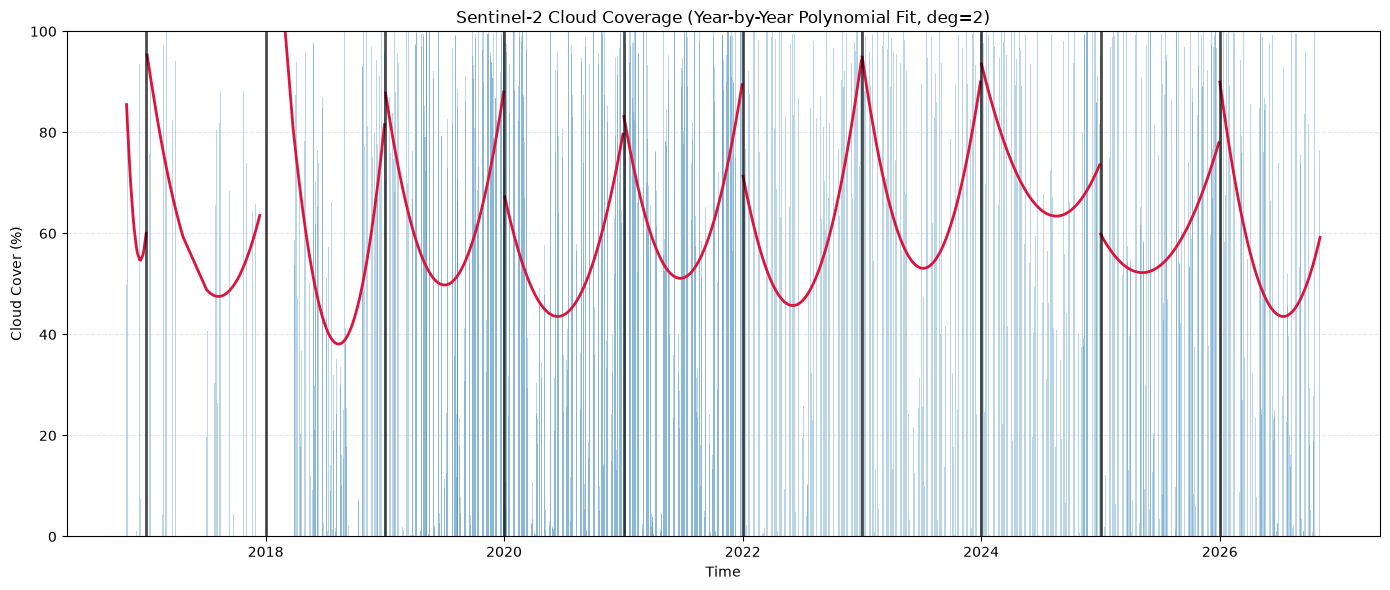

In [6]:
# Polynomial fit
deg = 2

# Assemble into a DataFrame for easy grouping
df = pd.DataFrame({"time": times, "x": x, "cloud_cover": y})
df["year"] = df["time"].dt.year

plt.figure(figsize=(14, 6))

# Plot raw acquisitions as background bars
plt.bar(times, y, width=1.5, color="tab:blue", alpha=0.3, label="Acquisitions")

# Fit and plot polynomial year by year
for year, group in df.groupby("year"):
    # Ensure there are enough data points to fit the requested degree
    if len(group) <= deg:
        continue
    
    x_year = group["x"].to_numpy()
    y_year = group["cloud_cover"].to_numpy()
    
    # Sort chronologically within the year for smooth line plotting
    sorted_idx = np.argsort(x_year)
    x_sorted = x_year[sorted_idx]
    times_sorted = group["time"].to_numpy()[sorted_idx]
    
    # Fit polynomial for this specific year
    coeffs = np.polyfit(x_year, y_year, deg)
    poly_func = np.poly1d(coeffs)
    y_poly = poly_func(x_sorted)
    
    # Plot the yearly trendline
    plt.plot(times_sorted, y_poly, color="crimson", linewidth=2.0)

# Add thick black vertical lines at the start of each year to separate them
unique_years = sorted(df["year"].unique())
for year in unique_years[1:]:
    boundary_date = pd.Timestamp(f"{year}-01-01")
    plt.axvline(x=boundary_date, color="black", linewidth=2.0, alpha=0.7)

plt.title(f"Sentinel-2 Cloud Coverage (Year-by-Year Polynomial Fit, deg={deg})")
plt.xlabel("Time")
plt.ylabel("Cloud Cover (%)")
plt.grid(True, linestyle="--", alpha=0.3, axis="y")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

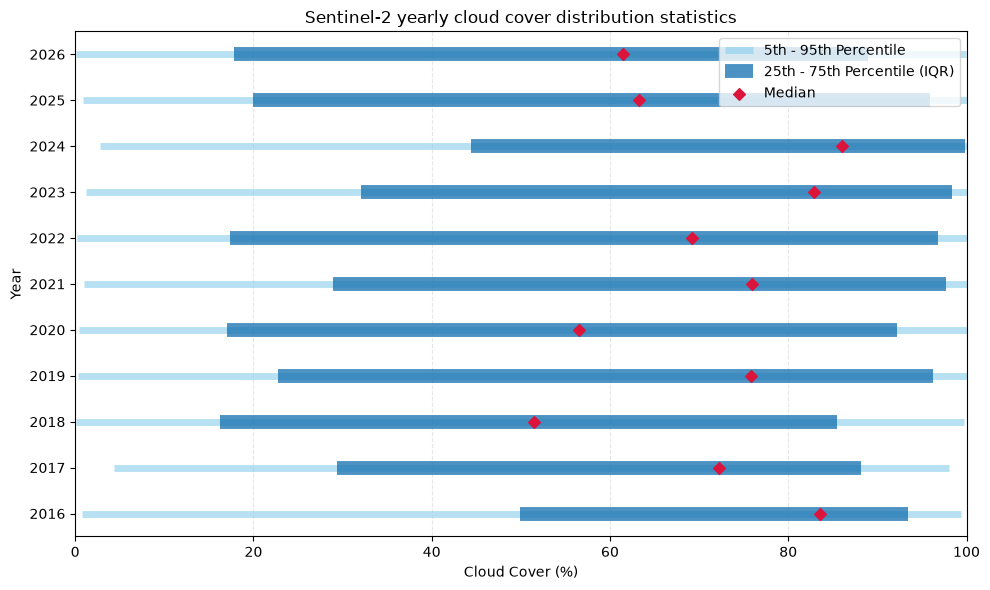

In [7]:
# Compute percentiles and median for each year
stats = []
for year, group in df.groupby("year"):
    cc = group["cloud_cover"].values
    if len(cc) == 0:
        continue
    stats.append({
        "year": str(year),
        "p5": np.percentile(cc, 5),
        "p25": np.percentile(cc, 25),
        "median": np.percentile(cc, 50),
        "p75": np.percentile(cc, 75),
        "p95": np.percentile(cc, 95),
    })

stats_df = pd.DataFrame(stats)

# Plotting horizontal summary bars
plt.figure(figsize=(10, max(6, len(stats_df) * 0.4)))

for i, row in stats_df.iterrows():
    yr = row["year"]
    
    # Outer range (5th to 95th percentile)
    plt.hlines(
        y=yr, xmin=row["p5"], xmax=row["p95"],
        color="skyblue", linewidth=5, alpha=0.6,
        label="5th - 95th Percentile" if i == 0 else ""
    )
    
    # Interquartile range (25th to 75th percentile)
    plt.hlines(
        y=yr, xmin=row["p25"], xmax=row["p75"],
        color="tab:blue", linewidth=10, alpha=0.8,
        label="25th - 75th Percentile (IQR)" if i == 0 else ""
    )
    
    # Median marker
    plt.scatter(
        row["median"], yr,
        marker="D", color="crimson", s=36, zorder=5,
        label="Median" if i == 0 else ""
    )

plt.xlabel("Cloud Cover (%)")
plt.ylabel("Year")
plt.title("Sentinel-2 yearly cloud cover distribution statistics")
plt.xlim(0, 100)
plt.grid(True, linestyle="--", alpha=0.3, axis="x")
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

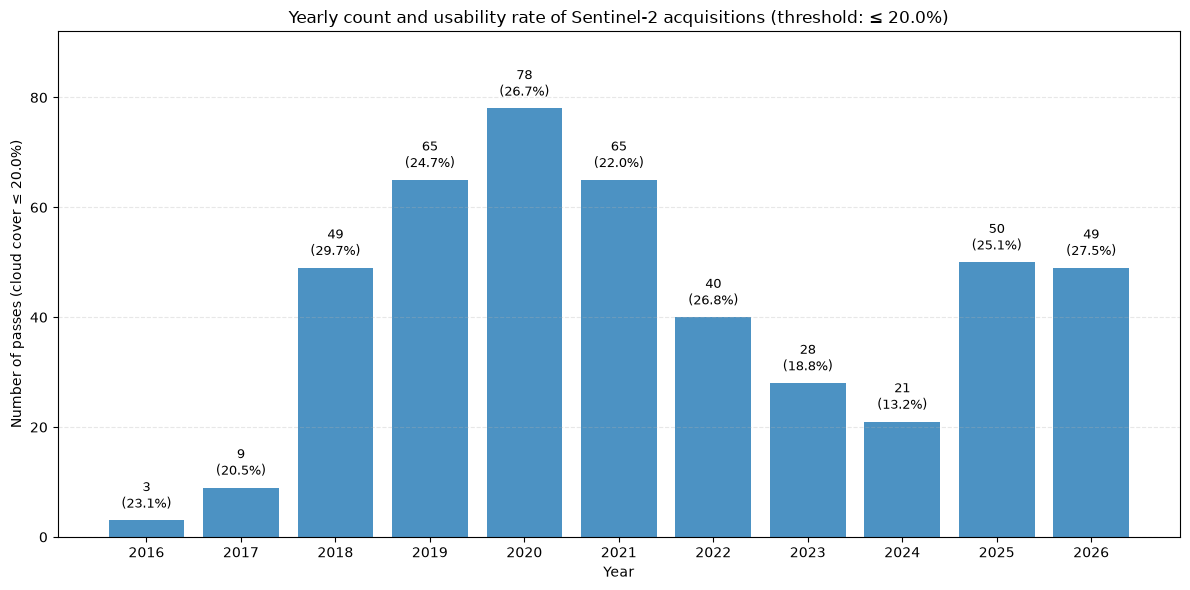

In [8]:
# Define your acceptable cloud coverage threshold
cloud_threshold = 20.0

# Filter dataframe for acquisitions meeting the threshold
df_filtered = df[df["cloud_cover"] <= cloud_threshold]

# Calculate hits per year and total available passes per year
hits_per_year = df_filtered.groupby("year").size()
total_per_year = df.groupby("year").size()

# Combine into a summary dataframe and compute the percentage of successful passes per year
summary_df = pd.DataFrame({"hits": hits_per_year, "total": total_per_year}).fillna(0)
summary_df["success_rate"] = (summary_df["hits"] / summary_df["total"]) * 100

years = summary_df.index.astype(str)
counts = summary_df["hits"].values
rates = summary_df["success_rate"].values

# Plotting
plt.figure(figsize=(12, 6))
bars = plt.bar(years, counts, color="tab:blue", alpha=0.8)

# Annotate each bar with the absolute count and the percentage of usable passes that year
for bar, count, rate in zip(bars, counts, rates):
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + max(counts) * 0.02 if len(counts) > 0 and max(counts) > 0 else 1,
        f"{int(count)}\n({rate:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=9,
    )

plt.xlabel("Year")
plt.ylabel(f"Number of passes (cloud cover ≤ {cloud_threshold}%)")
plt.title(f"Yearly count and usability rate of Sentinel-2 acquisitions (threshold: ≤ {cloud_threshold}%)")
plt.ylim(0, max(counts) * 1.18 if len(counts) > 0 and max(counts) > 0 else 10)
plt.grid(True, linestyle="--", alpha=0.3, axis="y")
plt.tight_layout()
plt.show()